In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist
from scipy.stats import wasserstein_distance
# import ot
import itertools
# from umap import UMAP

animal_data = pd.read_csv("Tierdaten/non_inv_params_long_list_constant_speed_all.csv", sep=';')
dfs = {animal: df_group for animal, df_group in animal_data.groupby('animal')}

print(dfs.keys())
print(animal_data.groupby('animal').size())

dict_keys([1, 3, 4, 7, 8, 10, 11, 13, 16, 17, 19, 20, 101, 102, 105, 107, 108, 111, 113, 502, 503, 505, 506])
animal
1      1853
3      1562
4      2381
7       915
8      1777
10     1508
11     2215
13      777
16     1828
17       63
19      934
20     1433
101     172
102     234
105     303
107     946
108     509
111     758
113    1449
502     298
503     471
505      81
506     178
dtype: int64


In [2]:
all_ids = [1, 3, 4, 8, 10, 11, 13, 16, 19, 20, 102, 105, 107, 108, 111, 113]

dfs_selected = {a: dfs[a] for a in all_ids if a in dfs}

df_selected = pd.concat(dfs_selected.values())

print(df_selected.groupby('animal').size())

df_selected.groupby('animal')['intervention'].value_counts()

animal
1      1853
3      1562
4      2381
8      1777
10     1508
11     2215
13      777
16     1828
19      934
20     1433
102     234
105     303
107     946
108     509
111     758
113    1449
dtype: int64


animal  intervention
1       4               1606
        3                183
        1                 64
3       1                564
        3                506
        10               292
        4                200
4       10               921
        3                886
        1                574
8       10               676
        1                648
        3                453
10      10               682
        1                538
        3                288
11      10              1416
        1                410
        3                389
13      10               375
        1                215
        3                187
16      10              1003
        3                545
        1                280
19      3                636
        1                298
20      10               785
        1                405
        3                243
102     1                234
105     1                123
        3                 98
        2             

In [3]:
cols = df_selected.columns[14:].drop("syst_share_p_head_by_byp_flow")
df_features = df_selected[cols]

data = {}
for aid in all_ids:
    mask = df_selected['animal'] == aid

    X = df_features[mask].reset_index(drop=True)
    Y = df_selected.loc[mask, ['sw']].reset_index(drop=True)
    Y.columns = ['target']

    data[aid] = (X, Y)


--- A. Target (Y) Pairwise 1D Wasserstein Distance Matrix ---
             Anim 1     Anim 3     Anim 4     Anim 8    Anim 10    Anim 11  \
Anim 1       0.0000   503.2089   545.9717   606.5296   982.3989   315.5810   
Anim 3     503.2089     0.0000   945.2243  1044.7911   665.3659   480.8383   
Anim 4     545.9717   945.2243     0.0000   311.0608  1378.9857   490.3391   
Anim 8     606.5296  1044.7911   311.0608     0.0000  1514.8336   567.7927   
Anim 10    982.3989   665.3659  1378.9857  1514.8336     0.0000   949.4748   
Anim 11    315.5810   480.8383   490.3391   567.7927   949.4748     0.0000   
Anim 13   1022.8381   532.3165  1443.4401  1571.0963   691.6972  1006.7334   
Anim 16    589.7745   130.0944  1013.1227  1099.4679   576.5781   537.3688   
Anim 19    953.8710   457.0005  1377.6837  1480.2333   695.1871   916.6643   
Anim 20    966.3575   465.7717  1397.1450  1482.2587   656.0345   919.4278   
Anim 102  1128.3306   635.7846  1546.9305  1666.1842   597.0016  1102.7871   
A

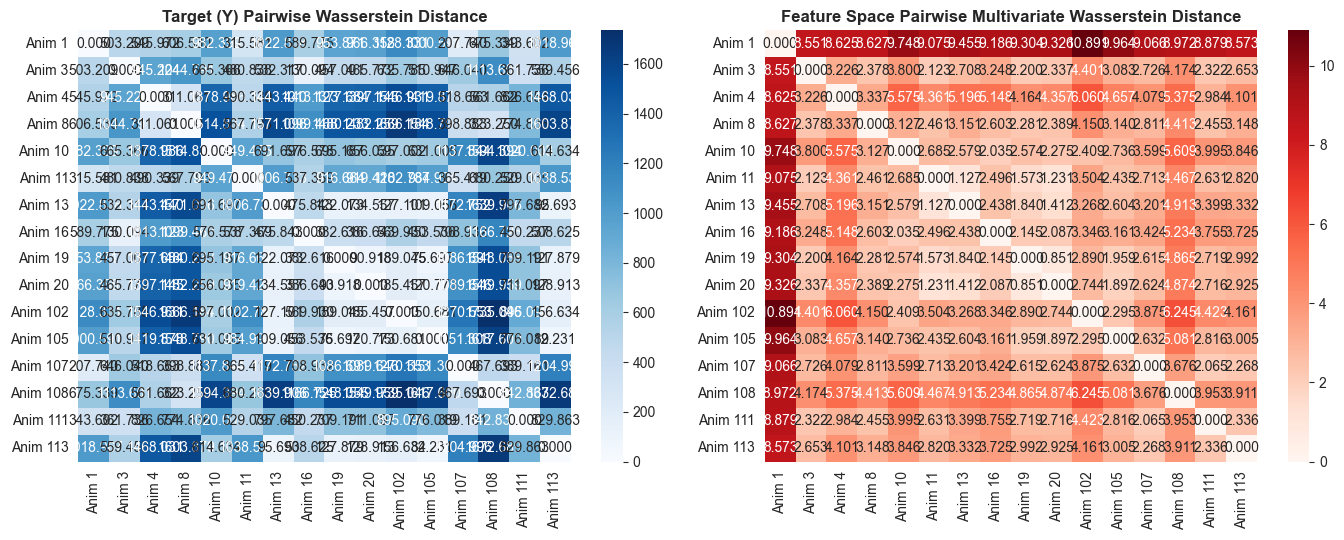

In [11]:
# W Distnace
# 1. Fit scaler on all data combined to ensure a uniform feature metric space
all_X_concat = pd.concat([data[aid][0] for aid in all_ids], axis=0)
scaler = StandardScaler()
scaler.fit(all_X_concat)

# 2. Store scaled features and target values per animal
scaled_X = {aid: scaler.transform(data[aid][0]) for aid in all_ids}
targets = {aid: data[aid][1]['target'].values for aid in all_ids}

animal_labels = [f"Anim {aid}" for aid in all_ids]
n_animals = len(all_ids)

# 3. Initialize distance matrices
y_w_matrix = pd.DataFrame(0.0, index=animal_labels, columns=animal_labels)
multi_w_matrix = pd.DataFrame(0.0, index=animal_labels, columns=animal_labels)


# 4. Compute pairwise distances
for i, id1 in enumerate(all_ids):
    for j, id2 in enumerate(all_ids):
        if i < j:
            # --- A. 1D Target (Y) Wasserstein Distance ---
            w_y = wasserstein_distance(targets[id1], targets[id2])
            y_w_matrix.iloc[i, j] = w_y
            y_w_matrix.iloc[j, i] = w_y  # Symmetric matrix

            # --- B. Multivariate Feature Space Wasserstein Distance ---
            X1 = scaled_X[id1]
            X2 = scaled_X[id2]

            # Cost Matrix: Squared Euclidean distances between all sample pairs
            M = ot.dist(X1, X2, metric='sqeuclidean')
            a = ot.unif(len(X1))
            b = ot.unif(len(X2))

            # Compute exact 2-Wasserstein distance
            w2_dist = np.sqrt(ot.emd2(a, b, M))

            multi_w_matrix.iloc[i, j] = w2_dist
            multi_w_matrix.iloc[j, i] = w2_dist

# 5. Print Tabular Results
print("\n--- A. Target (Y) Pairwise 1D Wasserstein Distance Matrix ---")
print(y_w_matrix.round(4))

print("\n--- B. Full Feature Space Pairwise Multivariate Wasserstein Distance Matrix ---")
print(multi_w_matrix.round(4))

# 6. Plot Pairwise Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(y_w_matrix, annot=True, fmt=".3f", cmap="Blues", cbar=True, ax=axes[0])
axes[0].set_title("Target (Y) Pairwise Wasserstein Distance", fontsize=12, fontweight='bold')

sns.heatmap(multi_w_matrix, annot=True, fmt=".3f", cmap="Reds", cbar=True, ax=axes[1])
axes[1].set_title("Feature Space Pairwise Multivariate Wasserstein Distance", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


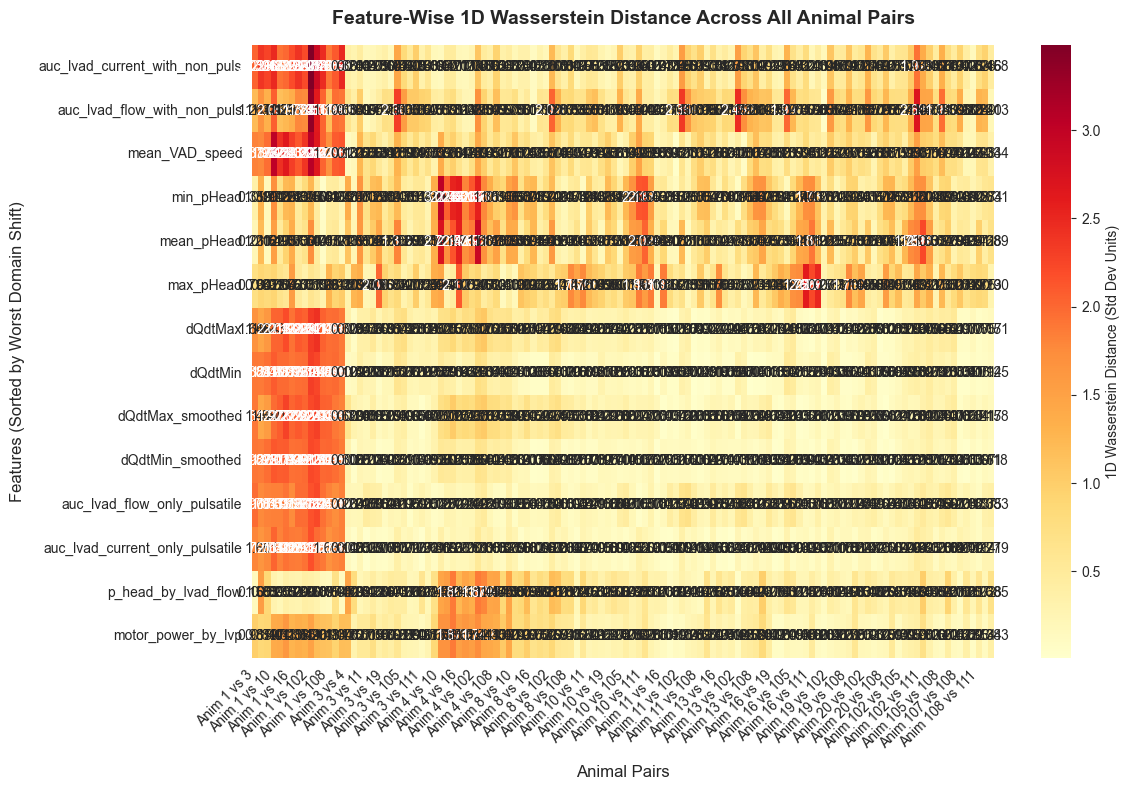

In [12]:
# W Distance per Feature
# 1. Fit scaler on all feature data combined for a uniform metric space
all_X_concat = pd.concat([data[aid][0] for aid in all_ids], axis=0)
scaler = StandardScaler()
scaler.fit(all_X_concat)

# 2. Scale features per animal while keeping feature column names
scaled_data = {}
for aid in all_ids:
    X_scaled_arr = scaler.transform(data[aid][0])
    scaled_data[aid] = pd.DataFrame(X_scaled_arr, columns=data[aid][0].columns)

# Get feature names (or indices)
sample_cols = data[all_ids[0]][0].columns
feature_names = [f"Feature {col}" if isinstance(col, int) else str(col) for col in sample_cols]

# 3. Generate all unique animal pairs (10 pairs for 5 animals)
animal_pairs = list(itertools.combinations(all_ids, 2))
pair_labels = [f"Anim {a1} vs {a2}" for a1, a2 in animal_pairs]

# Initialize matrix: Rows = Features, Columns = Animal Pairs
feature_w_matrix = pd.DataFrame(0.0, index=feature_names, columns=pair_labels)

# 4. Compute 1D Wasserstein distance per feature per animal pair
for (a1, a2), pair_label in zip(animal_pairs, pair_labels):
    df1 = scaled_data[a1]
    df2 = scaled_data[a2]
    
    for orig_col, feat_label in zip(sample_cols, feature_names):
        wd = wasserstein_distance(df1[orig_col], df2[orig_col])
        feature_w_matrix.loc[feat_label, pair_label] = wd

# Sort features by maximum shift observed across any pair (worst offenders at the top)
feature_w_matrix['max_shift'] = feature_w_matrix.max(axis=1)
feature_w_matrix = feature_w_matrix.sort_values(by='max_shift', ascending=False).drop(columns=['max_shift'])

# 5. Plot the Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    feature_w_matrix, 
    annot=True, 
    fmt=".3f", 
    cmap="YlOrRd", 
    cbar_kws={'label': '1D Wasserstein Distance (Std Dev Units)'}
)

plt.title("Feature-Wise 1D Wasserstein Distance Across All Animal Pairs", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Animal Pairs", fontsize=12, labelpad=10)
plt.ylabel("Features (Sorted by Worst Domain Shift)", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# split missing Anims into CSV files
import os

out_dir = "C:/Users/leona/PythonScripts/MasterThesis/Tierdaten/"  # change as needed
os.makedirs(out_dir, exist_ok=True)

animals = [11, 13, 16, 19, 20, 102, 105, 107, 108, 111, 113]

for aid in animals:
    mask = df_selected['animal'] == aid

    X = df_features[mask].reset_index(drop=True)
    Y = df_selected.loc[mask, ['sw']].reset_index(drop=True)
    Y.columns = ['target']

    X.to_csv(os.path.join(out_dir, f"X_anim{aid}.csv"), header=False, index=False)
    Y.to_csv(os.path.join(out_dir, f"Y_anim{aid}.csv"), header=False, index=False)

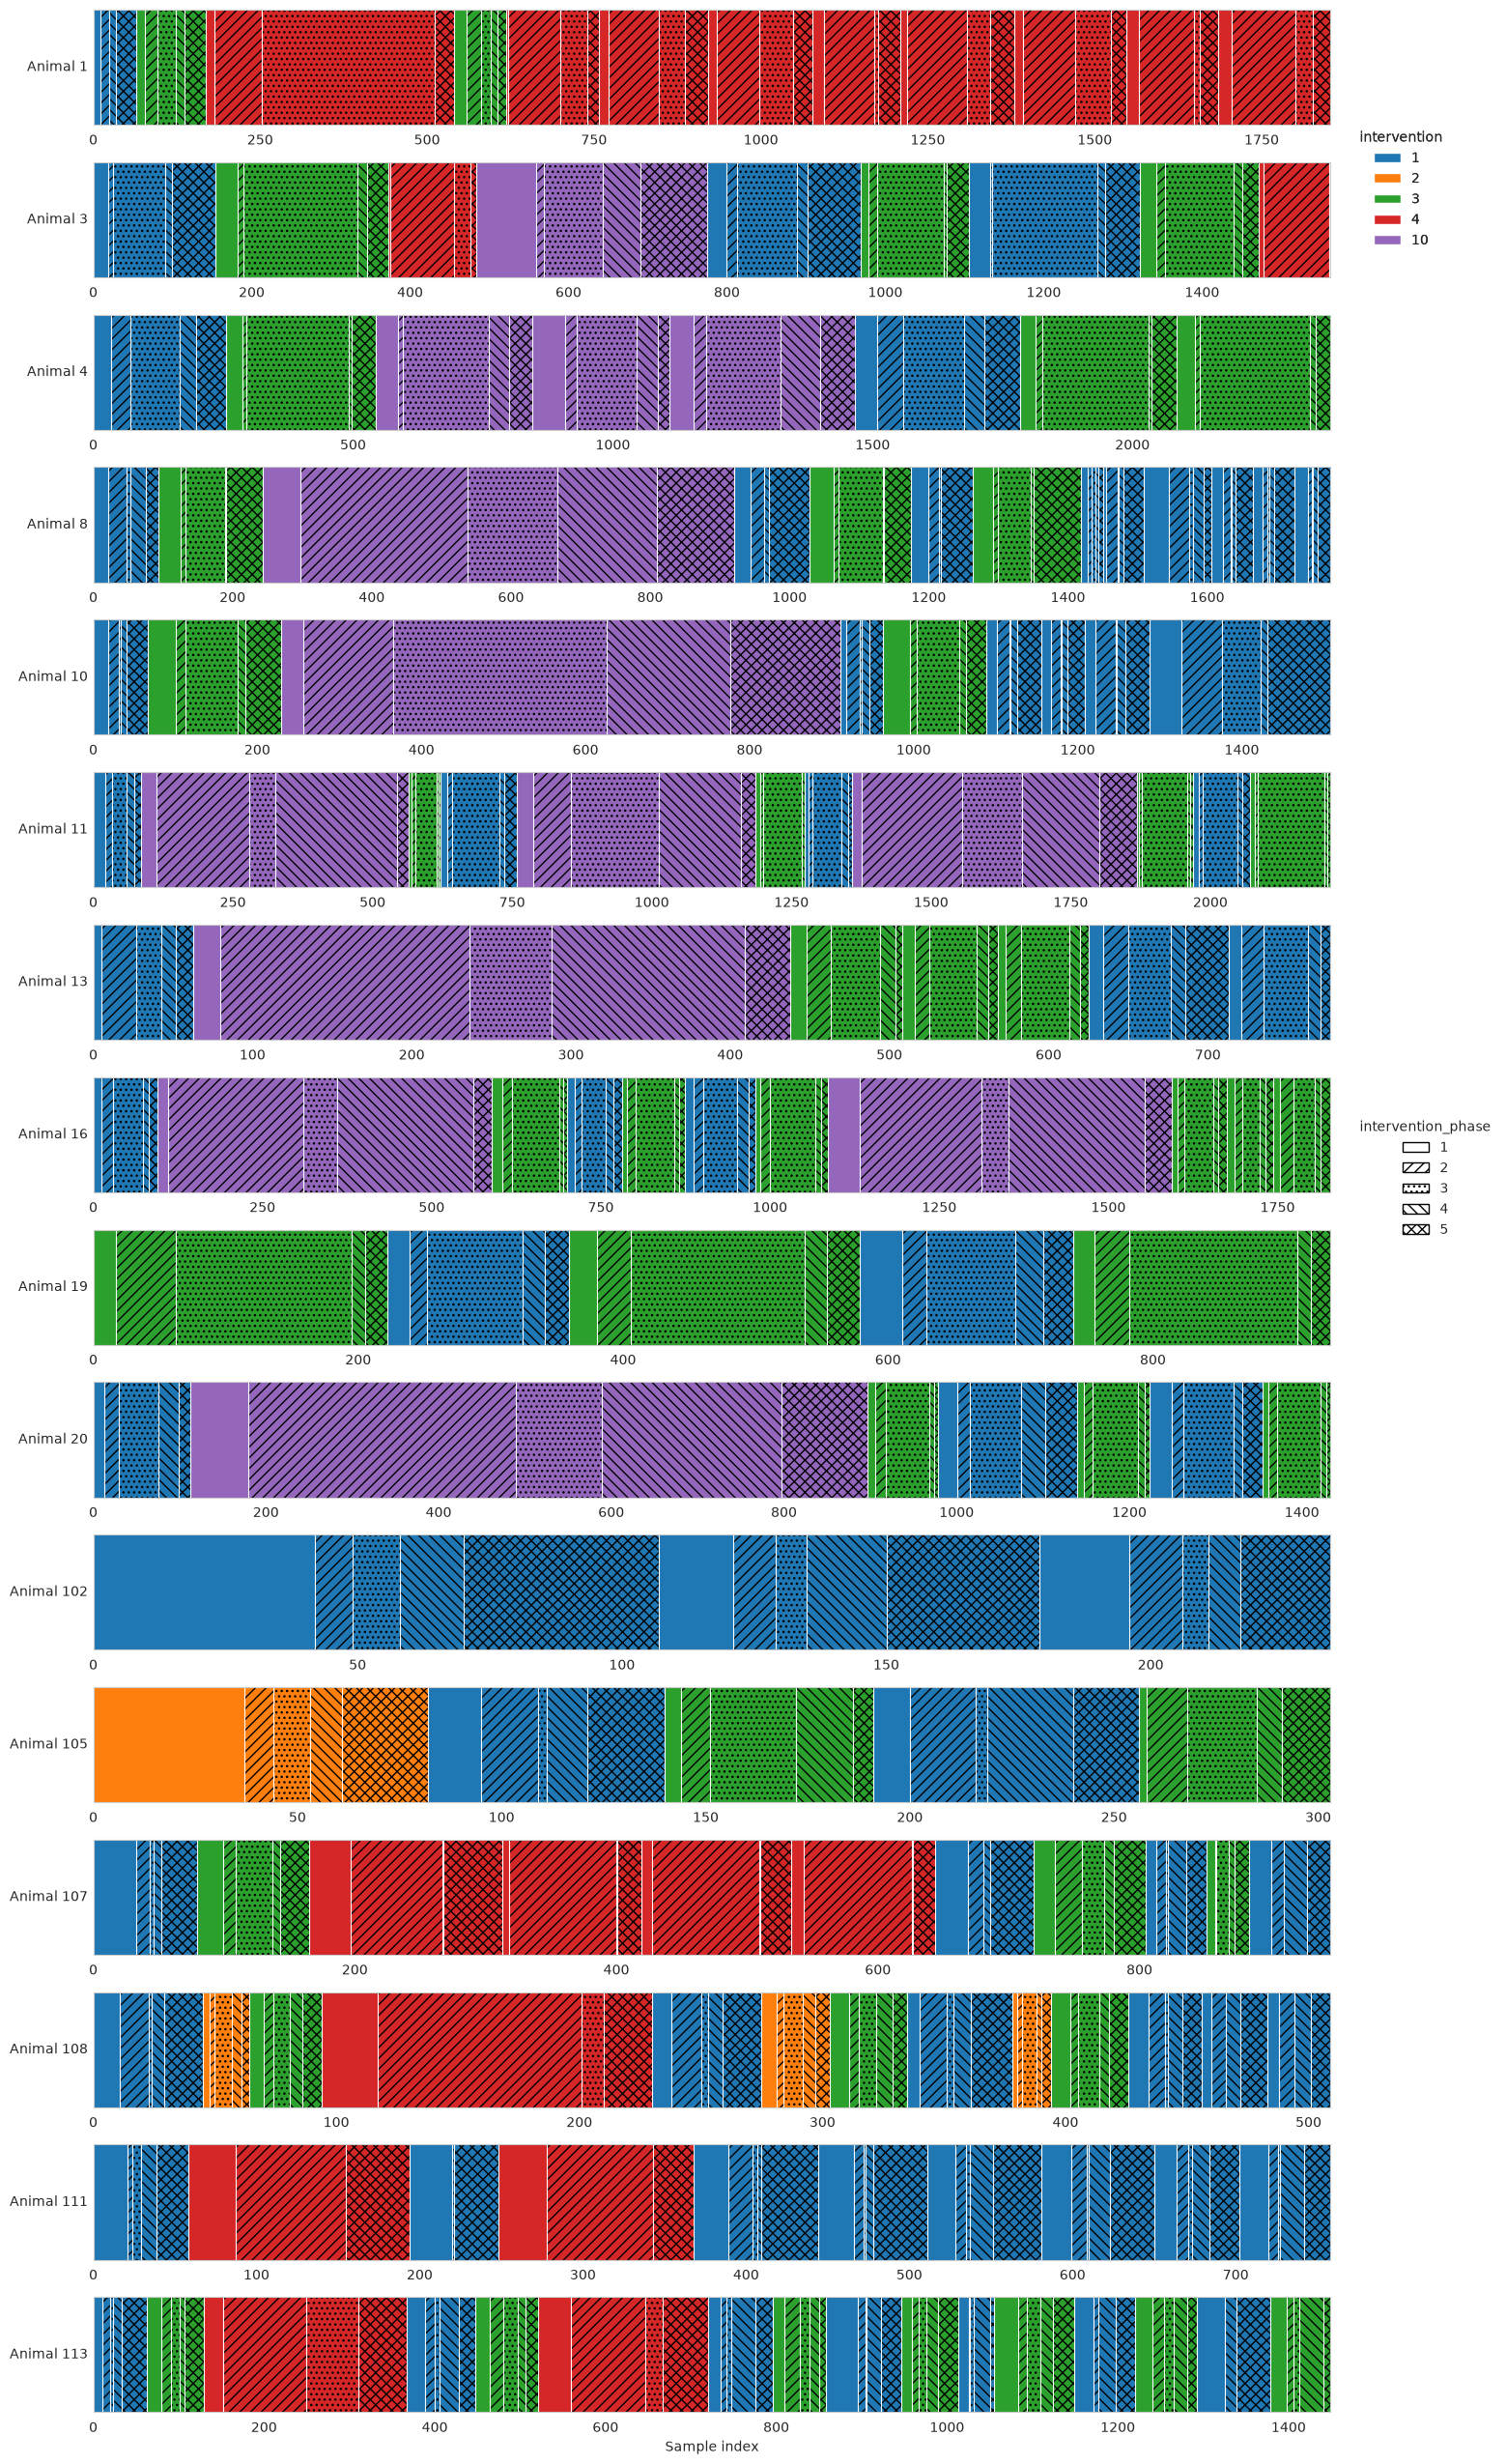

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def num_key(x):
    # numeric sort where possible (1, 2, 3, 4, 10), otherwise alphabetical
    try:
        return (0, float(x))
    except (TypeError, ValueError):
        return (1, str(x))

phases = sorted(pd.unique(df_selected['intervention'].dropna()), key=num_key)
sub_phases = sorted(pd.unique(df_selected['intervention_phase'].dropna()), key=num_key)

cmap = plt.get_cmap('tab10' if len(phases) <= 10 else 'tab20')
color_of = {p: cmap(i % cmap.N) for i, p in enumerate(phases)}
hatches = ['', '///', '...', 'xxx', '\\\\\\', '+++', 'ooo', '---']
hatch_of = {p: hatches[i % len(hatches)] for i, p in enumerate(sub_phases)}
p4 = next(p for p in hatch_of if num_key(p) == (0, 4.0))
p5 = next(p for p in hatch_of if num_key(p) == (0, 5.0))
hatch_of[p4], hatch_of[p5] = hatch_of[p5], hatch_of[p4]

fig, axes = plt.subplots(len(dfs_selected), 1, figsize=(14, 1.6 * len(dfs_selected)))
axes = np.atleast_1d(axes)

for ax, (animal, df_a) in zip(axes, dfs_selected.items()):
    d = df_a[['intervention', 'intervention_phase']].reset_index(drop=True)
    key = d['intervention'].astype(str) + '|' + d['intervention_phase'].astype(str)
    seg_id = (key != key.shift()).cumsum()

    for _, seg in d.groupby(seg_id):
        start, end = seg.index[0], seg.index[-1] + 1
        iv, ph = seg['intervention'].iloc[0], seg['intervention_phase'].iloc[0]
        ax.axvspan(start, end,
                   facecolor=color_of.get(iv, 'lightgrey'),
                   hatch=hatch_of.get(ph, ''),
                   edgecolor='black', lw=0)
        if start > 0:
            ax.axvline(start, color='white', lw=0.8)

    ax.set_xlim(0, len(d))
    ax.set_yticks([])
    ax.set_ylabel(f'Animal {animal}', rotation=0, ha='right', va='center')

axes[-1].set_xlabel('Sample index')

iv_handles = [mpatches.Patch(facecolor=color_of[p], label=str(p)) for p in phases]
ph_handles = [mpatches.Patch(facecolor='white', edgecolor='black',
                             hatch=hatch_of[p], label=str(p)) for p in sub_phases]

leg1 = fig.legend(handles=iv_handles, title='intervention', loc='upper left',
                  bbox_to_anchor=(1.0, 0.95), frameon=False)
fig.legend(handles=ph_handles, title='intervention_phase', loc='upper left',
           bbox_to_anchor=(1.0, 0.55), frameon=False)
fig.add_artist(leg1)

plt.tight_layout()
plt.show()